In [3]:
import zipfile
import glob
import os

# Mencari file ZIP di Google Colab
zip_files = glob.glob("/content/*.zip")
print("File ZIP ditemukan:", zip_files)

# Memeriksa isi ZIP dataset
zip_path = "/content/sentiment+labelled+sentences.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    print("\nIsi dataset ZIP:")
    for nama_file in z.namelist():
        print(nama_file)

File ZIP ditemukan: ['/content/sentiment+labelled+sentences.zip']

Isi dataset ZIP:
sentiment labelled sentences/
sentiment labelled sentences/.DS_Store
__MACOSX/
__MACOSX/sentiment labelled sentences/
__MACOSX/sentiment labelled sentences/._.DS_Store
sentiment labelled sentences/amazon_cells_labelled.txt
sentiment labelled sentences/imdb_labelled.txt
__MACOSX/sentiment labelled sentences/._imdb_labelled.txt
sentiment labelled sentences/readme.txt
__MACOSX/sentiment labelled sentences/._readme.txt
sentiment labelled sentences/yelp_labelled.txt
__MACOSX/._sentiment labelled sentences


In [4]:
import zipfile
import pandas as pd

# Lokasi file ZIP
zip_path = "/content/sentiment+labelled+sentences.zip"

# Nama file dataset di dalam ZIP
files = [
    "sentiment labelled sentences/amazon_cells_labelled.txt",
    "sentiment labelled sentences/imdb_labelled.txt",
    "sentiment labelled sentences/yelp_labelled.txt"
]

dataframes = []

# Membaca ketiga dataset
with zipfile.ZipFile(zip_path, "r") as z:
    for file in files:
        with z.open(file) as f:
            temp = pd.read_csv(
                f,
                sep="\t",
                header=None,
                names=["review", "sentiment"]
            )
            temp["source"] = file.split("/")[-1].replace(
                "_labelled.txt", ""
            )
            dataframes.append(temp)

# Menggabungkan semua dataset
df = pd.concat(dataframes, ignore_index=True)

# Pemeriksaan awal data
print("Ukuran dataset:", df.shape)

print("\nNama kolom:")
print(df.columns.tolist())

print("\nLima baris pertama:")
display(df.head())

print("\nJumlah data kosong:")
print(df.isnull().sum())

print("\nDistribusi sentimen:")
print(df["sentiment"].value_counts().sort_index())

Ukuran dataset: (2748, 3)

Nama kolom:
['review', 'sentiment', 'source']

Lima baris pertama:


,review,sentiment,source
0,So there is no way for me to plug it in here i...,0,amazon_cells
1,"Good case, Excellent value.",1,amazon_cells
2,Great for the jawbone.,1,amazon_cells
3,Tied to charger for conversations lasting more...,0,amazon_cells
4,The mic is great.,1,amazon_cells



Jumlah data kosong:
review       0
sentiment    0
source       0
dtype: int64

Distribusi sentimen:
sentiment
0    1362
1    1386
Name: count, dtype: int64


In [6]:
import zipfile

zip_path = "/content/sentiment+labelled+sentences.zip"

files = [
    "sentiment labelled sentences/amazon_cells_labelled.txt",
    "sentiment labelled sentences/imdb_labelled.txt",
    "sentiment labelled sentences/yelp_labelled.txt"
]

print("Jumlah data berdasarkan sumber:")
print(df["source"].value_counts())

print("\nPemeriksaan isi file ZIP:")

with zipfile.ZipFile(zip_path, "r") as z:
    for file in files:
        content = z.read(file).decode("utf-8")
        lines = content.splitlines()
        non_empty = [line for line in lines if line.strip()]

        print(f"\n{file.split('/')[-1]}")
        print("Jumlah seluruh baris:", len(lines))
        print("Jumlah baris tidak kosong:", len(non_empty))

Jumlah data berdasarkan sumber:
source
amazon_cells    1000
yelp            1000
imdb             748
Name: count, dtype: int64

Pemeriksaan isi file ZIP:

amazon_cells_labelled.txt
Jumlah seluruh baris: 1000
Jumlah baris tidak kosong: 1000

imdb_labelled.txt
Jumlah seluruh baris: 1002
Jumlah baris tidak kosong: 1002

yelp_labelled.txt
Jumlah seluruh baris: 1000
Jumlah baris tidak kosong: 1000


In [7]:
import zipfile
from collections import Counter

zip_path = "/content/sentiment+labelled+sentences.zip"
file = "sentiment labelled sentences/imdb_labelled.txt"

with zipfile.ZipFile(zip_path, "r") as z:
    text = z.read(file).decode("utf-8")

lines = text.splitlines()

# Menghitung jumlah tab pada setiap baris
tab_counts = Counter(line.count("\t") for line in lines)

print("Jumlah baris:", len(lines))
print("Distribusi jumlah tab per baris:", tab_counts)

print("\nContoh 10 baris pertama:")
for i, line in enumerate(lines[:10], start=1):
    print(f"{i}: {repr(line)}")

# Menampilkan contoh baris yang formatnya tidak biasa
print("\nContoh baris dengan jumlah tab bukan 1:")
shown = 0

for i, line in enumerate(lines, start=1):
    if line.count("\t") != 1:
        print(f"Baris {i}: {repr(line[:200])}")
        shown += 1

        if shown == 10:
            break

Jumlah baris: 1002
Distribusi jumlah tab per baris: Counter({1: 1000, 0: 2})

Contoh 10 baris pertama:
1: 'A very, very, very slow-moving, aimless movie about a distressed, drifting young man.  \t0'
2: 'Not sure who was more lost - the flat characters or the audience, nearly half of whom walked out.  \t0'
3: 'Attempting artiness with black & white and clever camera angles, the movie disappointed - became even more ridiculous - as the acting was poor and the plot and lines almost non-existent.  \t0'
4: 'Very little music or anything to speak of.  \t0'
5: 'The best scene in the movie was when Gerardo is trying to find a song that keeps running through his head.  \t1'
6: "The rest of the movie lacks art, charm, meaning... If it's about emptiness, it works I guess because it's empty.  \t0"
7: 'Wasted two hours.  \t0'
8: 'Saw the movie today and thought it was a good effort, good messages for kids.  \t1'
9: 'A bit predictable.  \t0'
10: 'Loved the casting of Jimmy Buffet as the science teac

In [8]:
import zipfile

zip_path = "/content/sentiment+labelled+sentences.zip"
file = "sentiment labelled sentences/imdb_labelled.txt"

with zipfile.ZipFile(zip_path, "r") as z:
    text = z.read(file).decode("utf-8")
    lines = text.splitlines()

# Tampilkan baris di sekitar kedua baris bermasalah
for target in [179, 969]:
    print(f"\n--- Sekitar baris {target} ---")

    start = max(1, target - 3)
    end = min(len(lines), target + 3)

    for i in range(start, end + 1):
        print(f"{i}: {repr(lines[i - 1])}")



--- Sekitar baris 179 ---
176: 'Everything is appalling.  \t0'
177: 'Artless camera-work endlessly presents us with the ugliest setting imaginable, i.e.  \t0'
178: 'The story is beyond stupid.  \t0'
179: 'The script is'
180: 'was there a script?  \t0'
181: 'The kids are annoying.  \t0'
182: 'The lead man is charisma-free.  \t0'

--- Sekitar baris 969 ---
966: 'The writer, Gorman Bechard, undoubtedly did his homework because all references are industry and character-age appropriate.  \t1'
967: 'The incredible soundtrack truly captures the essence of the film.  \t1'
968: 'Each track commands sentiment, actually contributing to the scenes and characters.  \t1'
969: 'Definitely worth seeing'
970: " it's the sort of thought provoking film that forces you to question your own threshold of loneliness.  \t1"
971: 'Hayao Miyazaki\'s latest and eighth film for Studio Ghibili, "Gake No Ue No Ponyo" (Ponyo on the Cliff by the Sea) is a wonderfully fun and imaginative look at childhood.  \t1'
972:

In [9]:
import zipfile
import pandas as pd

zip_path = "/content/sentiment+labelled+sentences.zip"

files = {
    "amazon_cells": "sentiment labelled sentences/amazon_cells_labelled.txt",
    "imdb": "sentiment labelled sentences/imdb_labelled.txt",
    "yelp": "sentiment labelled sentences/yelp_labelled.txt"
}

dataframes = []

with zipfile.ZipFile(zip_path, "r") as z:
    for source, file in files.items():
        text = z.read(file).decode("utf-8")
        lines = text.splitlines()

        records = []
        pending = ""

        for line in lines:
            if "\t" not in line:
                # Simpan potongan teks untuk digabungkan
                # dengan baris berlabel berikutnya
                pending += line.strip() + " "
                continue

            review, label = line.rsplit("\t", 1)

            # Gabungkan potongan teks jika ada
            review = (pending + review).strip()
            pending = ""

            records.append({
                "review": review,
                "sentiment": int(label.strip()),
                "source": source
            })

        if pending:
            print(f"Peringatan: ada potongan teks tersisa di {source}")

        dataframes.append(pd.DataFrame(records))

df = pd.concat(dataframes, ignore_index=True)

print("Ukuran dataset:", df.shape)

print("\nJumlah data per sumber:")
print(df["source"].value_counts())

print("\nDistribusi sentimen:")
print(df["sentiment"].value_counts().sort_index())

print("\nJumlah data kosong:")
print(df.isnull().sum())

print("\nLima baris pertama:")
display(df.head())

Ukuran dataset: (3000, 3)

Jumlah data per sumber:
source
amazon_cells    1000
imdb            1000
yelp            1000
Name: count, dtype: int64

Distribusi sentimen:
sentiment
0    1500
1    1500
Name: count, dtype: int64

Jumlah data kosong:
review       0
sentiment    0
source       0
dtype: int64

Lima baris pertama:


,review,sentiment,source
0,So there is no way for me to plug it in here i...,0,amazon_cells
1,"Good case, Excellent value.",1,amazon_cells
2,Great for the jawbone.,1,amazon_cells
3,Tied to charger for conversations lasting more...,0,amazon_cells
4,The mic is great.,1,amazon_cells


Distribusi Sentimen:
sentiment
Negatif    1500
Positif    1500
Name: count, dtype: int64


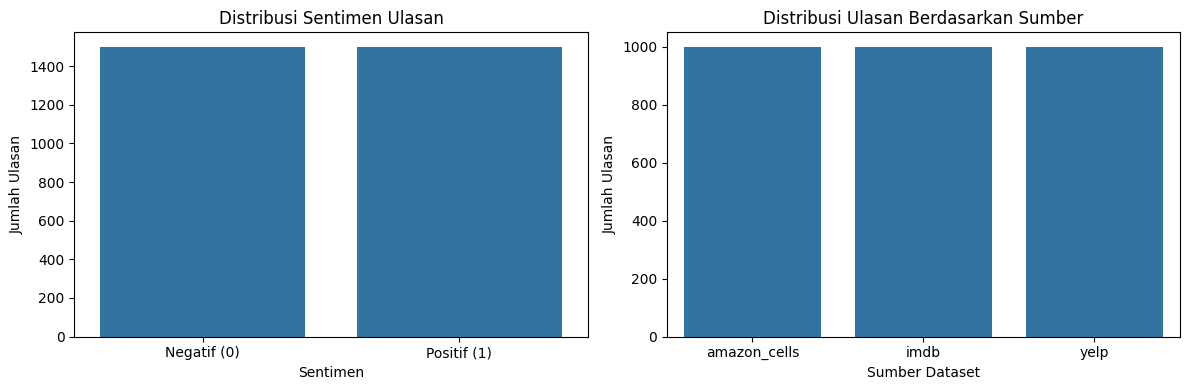

In [12]:
from sklearn.model_selection import train_test_split

# Memisahkan fitur teks dan target sentimen
X = df["review"]
y = df["sentiment"]

# Membagi data: 80% training dan 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Memeriksa hasil pembagian
print("Jumlah seluruh data:", len(df))
print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

print("\nDistribusi sentimen data latih:")
print(y_train.value_counts().sort_index())

print("\nDistribusi sentimen data uji:")
print(y_test.value_counts().sort_index())

Jumlah seluruh data: 3000
Jumlah data latih: 2400
Jumlah data uji: 600

Distribusi sentimen data latih:
sentiment
0    1200
1    1200
Name: count, dtype: int64

Distribusi sentimen data uji:
sentiment
0    300
1    300
Name: count, dtype: int64


In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# 1. Mengubah teks menjadi fitur numerik menggunakan TF-IDF
tfidf = TfidfVectorizer(
    lowercase=True,
    max_features=5000,
    ngram_range=(1, 2)
)

# Vectorizer hanya belajar dari data latih
X_train_tfidf = tfidf.fit_transform(X_train)

# Data uji hanya ditransformasikan, bukan dipakai untuk belajar kosakata
X_test_tfidf = tfidf.transform(X_test)

print("Jumlah fitur TF-IDF:", len(tfidf.get_feature_names_out()))
print("Bentuk data latih:", X_train_tfidf.shape)
print("Bentuk data uji:", X_test_tfidf.shape)

# 2. Membuat dan melatih model Logistic Regression
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_tfidf, y_train)

print("\nModel Logistic Regression berhasil dilatih.")
print("Kelas yang dipelajari model:", model.classes_)

Jumlah fitur TF-IDF: 5000
Bentuk data latih: (2400, 5000)
Bentuk data uji: (600, 5000)

Model Logistic Regression berhasil dilatih.
Kelas yang dipelajari model: [0 1]


=== HASIL EVALUASI MODEL ===
Accuracy  : 0.8283
Precision : 0.8147
Recall    : 0.8500
F1-Score  : 0.8320
AUC       : 0.9014

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

     Negatif       0.84      0.81      0.82       300
     Positif       0.81      0.85      0.83       300

    accuracy                           0.83       600
   macro avg       0.83      0.83      0.83       600
weighted avg       0.83      0.83      0.83       600



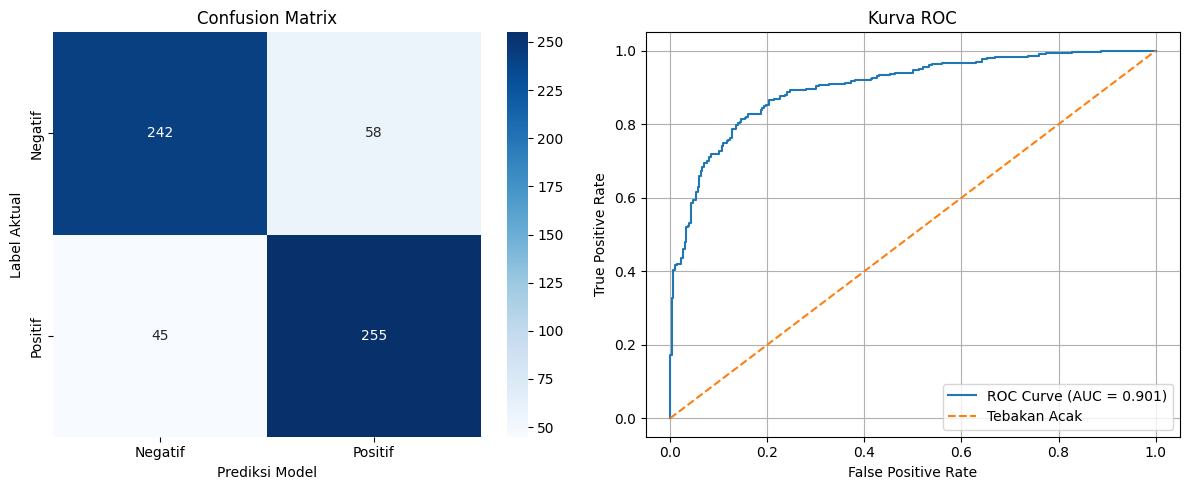

In [16]:
import joblib

# Memuat kembali model dan TF-IDF dari file
loaded_model = joblib.load("logistic_regression_model.joblib")
loaded_tfidf = joblib.load("tfidf_vectorizer.joblib")

# Contoh ulasan untuk pengujian
reviews = [
    "The product is excellent and works perfectly.",
    "This product is terrible and disappointing."
]

# Mengubah teks menjadi fitur numerik
reviews_tfidf = loaded_tfidf.transform(reviews)

# Melakukan prediksi
predictions = loaded_model.predict(reviews_tfidf)
probabilities = loaded_model.predict_proba(reviews_tfidf)

# Menampilkan hasil
for review, prediction, probability in zip(
    reviews, predictions, probabilities
):
    sentiment = "Positif" if prediction == 1 else "Negatif"
    confidence = probability[prediction] * 100

    print("Ulasan:", review)
    print("Prediksi:", sentiment)
    print(f"Probabilitas kelas prediksi: {confidence:.2f}%")
    print("-" * 50)

Ulasan: The product is excellent and works perfectly.
Prediksi: Positif
Probabilitas kelas prediksi: 87.28%
--------------------------------------------------
Ulasan: This product is terrible and disappointing.
Prediksi: Negatif
Probabilitas kelas prediksi: 74.59%
--------------------------------------------------


In [17]:
import zipfile
from google.colab import files

# Menggabungkan kedua file model ke dalam satu ZIP
with zipfile.ZipFile(
    "sentiment_model_files.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:
    zipf.write("logistic_regression_model.joblib")
    zipf.write("tfidf_vectorizer.joblib")

print("File model berhasil dikemas.")

# Mengunduh ZIP ke komputer
files.download("sentiment_model_files.zip")

File model berhasil dikemas.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>